# Chapter 21: Fokker–Planck and Distribution Dynamics
## Interactive Python & PyTorch Companion Notebook (Series Capstone)

Welcome to the companion coding notebook for **Chapter 21: Fokker–Planck and Distribution Dynamics**. In this capstone notebook, we verify all five exercise modules from `exercises/math.md` through PDE simulations, analytical identities, and PyTorch automatic differentiation:

1. **Exercises 1 & 2 (1D Fokker–Planck PDE & Probability Current $\mathbf{J}_t$):** Solving the 1D Fokker–Planck equation $\partial_t p_t + \partial_x J_t = 0$ ($J_t = f p_t - \frac{1}{2}\partial_x(D p_t)$) via finite differences on a bimodal double-well potential, verifying exact probability mass conservation $\int p_t(x)\,dx = 1$, and comparing against Monte Carlo Euler–Maruyama SDE particles.
2. **Exercise 3 (Langevin Stationarity & Monotonic KL Dissipation / Wasserstein Gradient Flow):** Verifying detailed balance ($J_*(x) \equiv 0$) at equilibrium $p_*(x) \propto e^{-V(x)}$, and demonstrating the exact dissipation law:
   $$\frac{d}{dt}D_{\mathrm{KL}}(p_t \parallel p) = -I(p_t \parallel p) = -\int p_t(\mathbf{x})\left\|\nabla\log\frac{p_t(\mathbf{x})}{p(\mathbf{x})}\right\|_2^2 d\mathbf{x} \le 0.$$
3. **Exercise 4 (Heat Equation vs VP-SDE Stationary Gaussian):** Contrasting unbounded variance growth $\mathrm{Var}(X_t) = \mathrm{Var}(X_0) + \beta t$ under the pure heat equation against the Variance-Preserving SDE (VP-SDE), which converges to the stationary standard Gaussian prior $\mathcal{N}(\mathbf{0}, \mathbf{I})$.
4. **Exercise 5 (Probability Flow ODE & Instantaneous Change of Variables):** Evaluating exact log-likelihoods $\log p_0(\mathbf{x}_0) = \log p_T(\mathbf{x}_T) + \int_0^T \nabla\cdot\mathbf{v}_t(\mathbf{x}_t)\,dt$ using both the exact Jacobian trace and the **Skilling–Hutchinson stochastic trace estimator** in PyTorch.

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})

np.random.seed(42)
torch.manual_seed(42)
print("Environment initialized successfully.")

Environment initialized successfully.


---
## 1. Exercises 1 & 2: 1D Fokker–Planck PDE, Probability Current & Mass Conservation

For the 1D Itô SDE $dX_t = f(X_t)\,dt + \sigma\,dW_t$ ($D = \sigma^2$), the density $p_t(x)$ satisfies the **Fokker–Planck equation**:
$$\partial_t p_t(x) = -\partial_x\!\left[f(x)p_t(x)\right] + \frac{1}{2}\sigma^2 \partial_{xx} p_t(x) = -\partial_x J_t(x),$$
where the **probability current (flux)** is:
$$J_t(x) = f(x)p_t(x) - \frac{1}{2}\sigma^2 \partial_x p_t(x).$$
At equilibrium $p_*(x) \propto \exp\!\left(\frac{2}{\sigma^2}\int f(x)\,dx\right)$, the probability flux vanishes identically ($J_*(x) \equiv 0$, **detailed balance**).

Total probability mass at t = [0.0, 0.15, 1.20]: [np.float64(1.0), np.float64(1.0), np.float64(1.0)]
L1 norm of probability current ||J_t||_1: t=0 -> 1.5515 | t=1.2 -> 0.1541


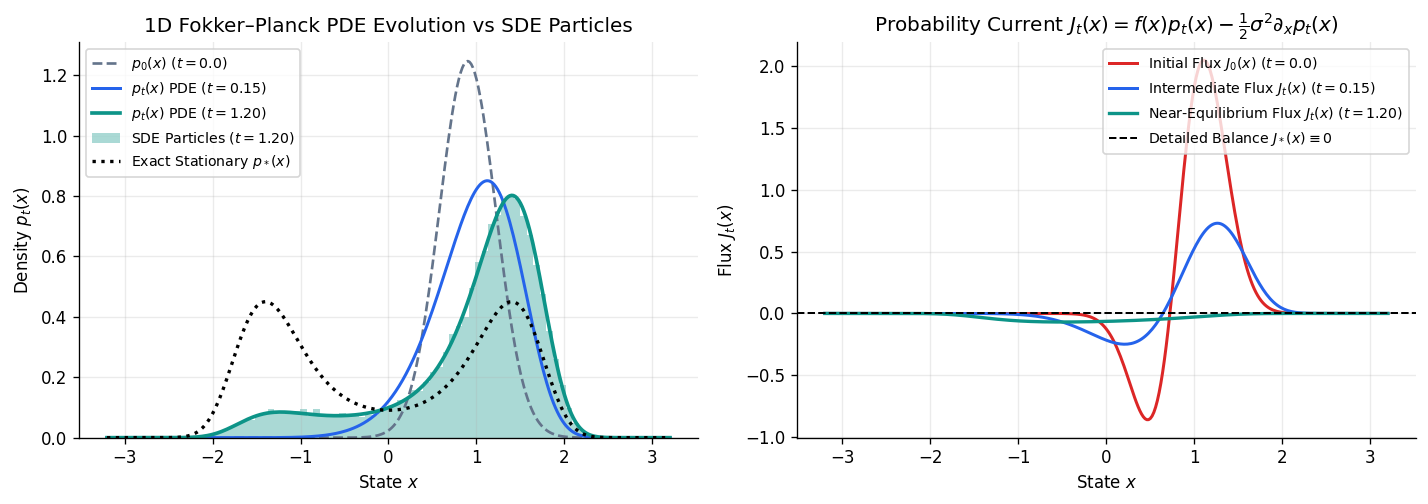

In [2]:
# Double-well potential V(x) = 0.25 * (x^2 - 1.4^2)^2 => drift f(x) = -V'(x) = -x * (x^2 - 1.96)
a_well = 1.4
sigma_fp = np.sqrt(1.2)  # D = sigma^2 = 1.2
D_fp = sigma_fp ** 2

x_fp = np.linspace(-3.2, 3.2, 321)
dx_fp = x_fp[1] - x_fp[0]
dt_fp = 1e-4
n_steps_fp = 12000  # T = 1.2

def drift_fn(x):
    return -x * (x ** 2 - a_well ** 2)

# Initial density: localized Gaussian centered at x = +0.9
p_init = np.exp(-0.5 * ((x_fp - 0.9) / 0.32) ** 2)
p_init /= np.sum(p_init) * dx_fp

# Exact stationary Gibbs density: p_*(x) \propto exp(-2 * V(x) / D)
V_x = 0.25 * (x_fp ** 2 - a_well ** 2) ** 2
p_stationary = np.exp(-2.0 * V_x / D_fp)
p_stationary /= np.sum(p_stationary) * dx_fp

# Finite-volume conservative PDE integration: dp/dt = -dJ/dx with zero boundary flux
p_curr = p_init.copy()
f_grid = drift_fn(x_fp)
snapshots = {0: p_curr.copy()}
masses_fp = [np.sum(p_curr) * dx_fp]

for step in range(1, n_steps_fp + 1):
    # Compute probability current J at cell centers, enforce J=0 at boundaries
    J_curr = f_grid * p_curr - 0.5 * D_fp * np.gradient(p_curr, dx_fp)
    J_curr[0] = 0.0
    J_curr[-1] = 0.0
    p_curr = p_curr - dt_fp * np.gradient(J_curr, dx_fp)
    if step in [1500, 12000]:
        snapshots[step] = p_curr.copy()
        masses_fp.append(np.sum(p_curr) * dx_fp)

# Simulate 25,000 Euler-Maruyama SDE particles up to T = 1.2 for comparison
n_particles = 25000
x_sde = 0.9 + 0.32 * np.random.randn(n_particles)
dt_sde = 0.002
for _ in range(int(1.2 / dt_sde)):
    x_sde = x_sde + drift_fn(x_sde) * dt_sde + sigma_fp * np.sqrt(dt_sde) * np.random.randn(n_particles)

# Check probability current norm ||J_t||_L1 at t=0 vs t=1.2
J_t0 = f_grid * p_init - 0.5 * D_fp * np.gradient(p_init, dx_fp)
J_tT = f_grid * p_curr - 0.5 * D_fp * np.gradient(p_curr, dx_fp)
print(f"Total probability mass at t = [0.0, 0.15, 1.20]: {[round(m, 5) for m in masses_fp]}")
print(f"L1 norm of probability current ||J_t||_1: t=0 -> {np.sum(np.abs(J_t0))*dx_fp:.4f} | t=1.2 -> {np.sum(np.abs(J_tT))*dx_fp:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))

axes[0].plot(x_fp, snapshots[0], "--", color="#64748b", lw=1.6, label="$p_0(x)$ ($t=0.0$)")
axes[0].plot(x_fp, snapshots[1500], color="#2563eb", lw=1.8, label="$p_t(x)$ PDE ($t=0.15$)")
axes[0].plot(x_fp, snapshots[12000], color="#0d9488", lw=2.2, label="$p_t(x)$ PDE ($t=1.20$)")
axes[0].hist(x_sde, bins=65, density=True, alpha=0.35, color="#0d9488", label="SDE Particles ($t=1.20$)")
axes[0].plot(x_fp, p_stationary, "k:", lw=2.0, label="Exact Stationary $p_*(x)$")
axes[0].set_title("1D Fokker–Planck PDE Evolution vs SDE Particles")
axes[0].set_xlabel("State $x$")
axes[0].set_ylabel("Density $p_t(x)$")
axes[0].legend(loc="upper left", fontsize=8.5)

axes[1].plot(x_fp, J_t0, color="#dc2626", lw=1.8, label="Initial Flux $J_0(x)$ ($t=0.0$)")
axes[1].plot(x_fp, f_grid * snapshots[1500] - 0.5 * D_fp * np.gradient(snapshots[1500], dx_fp), color="#2563eb", lw=1.8, label="Intermediate Flux $J_t(x)$ ($t=0.15$)")
axes[1].plot(x_fp, J_tT, color="#0d9488", lw=2.0, label="Near-Equilibrium Flux $J_t(x)$ ($t=1.20$)")
axes[1].axhline(0.0, color="k", ls="--", lw=1.2, label="Detailed Balance $J_*(x) \\equiv 0$")
axes[1].set_title("Probability Current $J_t(x) = f(x)p_t(x) - \\frac{1}{2}\\sigma^2 \\partial_x p_t(x)$")
axes[1].set_xlabel("State $x$")
axes[1].set_ylabel("Flux $J_t(x)$")
axes[1].legend(loc="upper right", fontsize=8.5)

plt.tight_layout()
plt.show()

---
## 2. Exercise 3: Monotonic KL Dissipation & Relative Fisher Information

For the overdamped Langevin SDE $d\mathbf{X}_t = \nabla\log p(\mathbf{X}_t)\,dt + \sqrt{2}\,d\mathbf{W}_t$, the Fokker–Planck equation can be written in continuity form:
$$\partial_t p_t = \nabla\cdot\!\left(p_t \nabla\log\frac{p_t}{p}\right).$$
Integrating by parts gives the fundamental **Wasserstein Gradient Flow dissipation identity**:
$$\frac{d}{dt}D_{\mathrm{KL}}(p_t \parallel p) = -\int_{\mathbb{R}^d} p_t(\mathbf{x})\left\|\nabla\log\frac{p_t(\mathbf{x})}{p(\mathbf{x})}\right\|_2^2 d\mathbf{x} = -I(p_t \parallel p) \le 0.$$

Initial KL Divergence D_KL(p_0 || p) = 2.8247 -> Final D_KL(p_T || p) = 0.01631
Max discrepancy |d/dt D_KL(p_t || p) + I(p_t || p)| = 0.003059


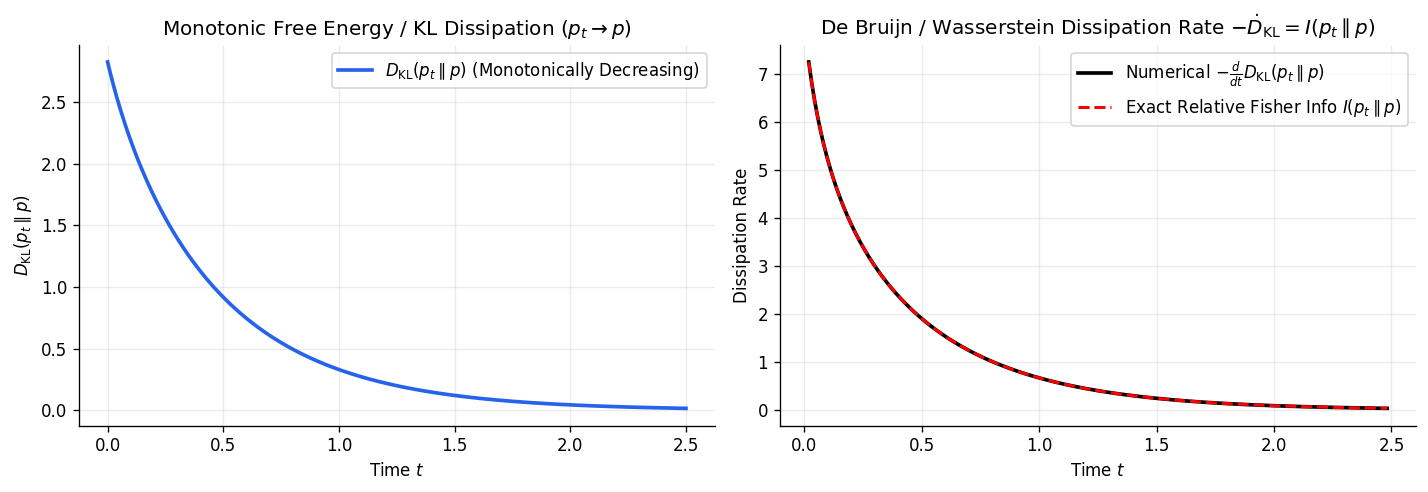

In [3]:
# Exact verification for 1D Langevin SDE targeting p = N(0, 1): dX_t = -X_t dt + sqrt(2) dW_t
# Starting from p_0 = N(m0, v0), p_t is Gaussian N(m_t, v_t) with:
#   m_t = m0 * exp(-t),   v_t = 1 + (v0 - 1) * exp(-2t)
t_kl = np.linspace(0.0, 2.5, 400)
dt_kl = t_kl[1] - t_kl[0]
m0_kl, v0_kl = 2.2, 0.20

m_t = m0_kl * np.exp(-t_kl)
v_t = 1.0 + (v0_kl - 1.0) * np.exp(-2.0 * t_kl)

# Exact KL divergence D_KL(p_t || p)
kl_exact = 0.5 * (m_t ** 2 + v_t - 1.0 - np.log(v_t))

# Exact Relative Fisher Information I(p_t || p) = E_{p_t}[ (-(x - m_t)/v_t + x)^2 ]
fisher_rel = m_t ** 2 + ((v_t - 1.0) ** 2) / v_t

# Numerical time derivative d/dt D_KL(p_t || p)
dkl_dt_numerical = np.gradient(kl_exact, dt_kl)
max_dissipation_err = np.max(np.abs(dkl_dt_numerical[3:-3] + fisher_rel[3:-3]))

print(f"Initial KL Divergence D_KL(p_0 || p) = {kl_exact[0]:.4f} -> Final D_KL(p_T || p) = {kl_exact[-1]:.5f}")
print(f"Max discrepancy |d/dt D_KL(p_t || p) + I(p_t || p)| = {max_dissipation_err:.6f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

axes[0].plot(t_kl, kl_exact, color="#2563eb", lw=2.2, label=r"$D_{\mathrm{KL}}(p_t \parallel p)$ (Monotonically Decreasing)")
axes[0].set_title(r"Monotonic Free Energy / KL Dissipation ($p_t \to p$)")
axes[0].set_xlabel("Time $t$")
axes[0].set_ylabel(r"$D_{\mathrm{KL}}(p_t \parallel p)$")
axes[0].legend(loc="upper right")

axes[1].plot(t_kl[3:-3], -dkl_dt_numerical[3:-3], "k-", lw=2.2, label=r"Numerical $-\frac{d}{dt}D_{\mathrm{KL}}(p_t \parallel p)$")
axes[1].plot(t_kl[3:-3], fisher_rel[3:-3], "r--", lw=1.8, label=r"Exact Relative Fisher Info $I(p_t \parallel p)$")
axes[1].set_title(r"De Bruijn / Wasserstein Dissipation Rate $-\dot{D}_{\mathrm{KL}} = I(p_t \parallel p)$")
axes[1].set_xlabel("Time $t$")
axes[1].set_ylabel("Dissipation Rate")
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()

---
## 3. Exercise 4: Pure Heat Equation vs Variance-Preserving SDE (VP-SDE)

1. **Pure Heat Equation ($\partial_t p_t = \frac{1}{2}\beta \nabla^2 p_t$):** Corresponds to $X_t = X_0 + \sqrt{\beta}W_t$, so $\mathrm{Var}(X_t) = \mathrm{Var}(X_0) + \beta t \to \infty$ linearly without bound.
2. **VP-SDE ($d\mathbf{X}_t = -\frac{1}{2}\beta\mathbf{X}_t\,dt + \sqrt{\beta}\,d\mathbf{W}_t$):** Adds an inward linear restoring drift $-\frac{1}{2}\beta\mathbf{X}_t$, so $\mathrm{Var}(X_t) = e^{-\beta t}\mathrm{Var}(X_0) + (1 - e^{-\beta t}) \to 1$, stabilizing to $\mathcal{N}(\mathbf{0}, \mathbf{I})$.

At terminal time T = 4.0:
  Heat Equation Variance: Empirical = 4.9720 | Exact Var(X_0) + beta*T = 5.0500
  VP-SDE Variance:        Empirical = 1.0068 | Exact Stationary Target = 0.9938


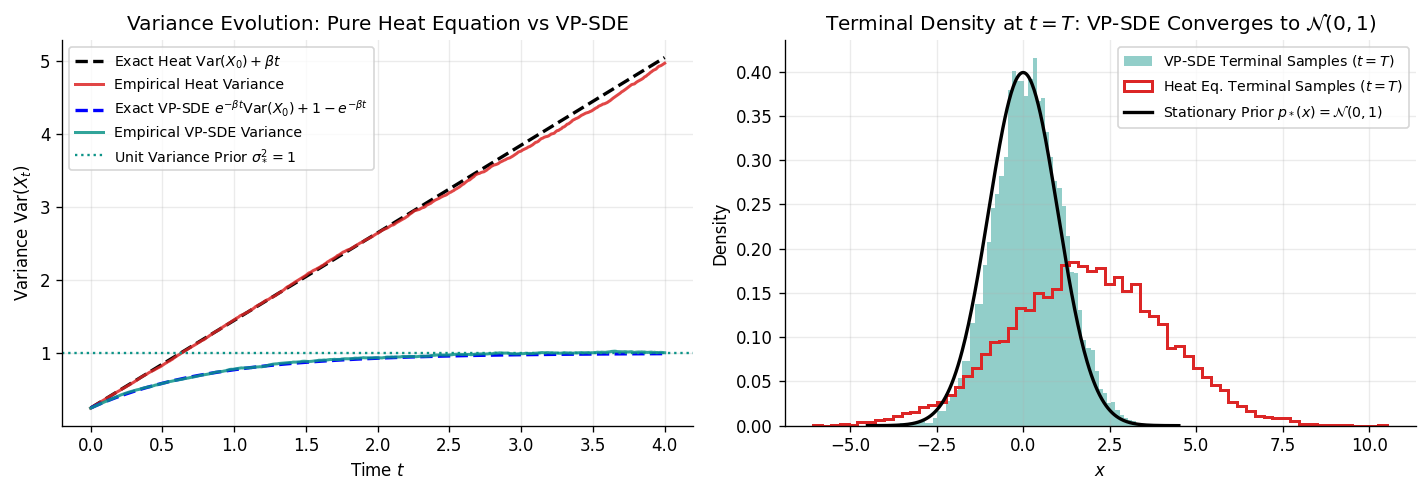

In [4]:
beta_val = 1.2
var0_val = 0.25
T_heat = 4.0
n_steps_heat = 400
dt_heat = T_heat / n_steps_heat
t_heat = np.linspace(0.0, T_heat, n_steps_heat + 1)

n_mc = 10000
x0_mc = 1.8 + np.sqrt(var0_val) * np.random.randn(n_mc)

x_heat_paths = np.zeros((n_mc, n_steps_heat + 1))
x_vp_paths = np.zeros((n_mc, n_steps_heat + 1))
x_heat_paths[:, 0] = x0_mc
x_vp_paths[:, 0] = x0_mc

for k in range(n_steps_heat):
    noise_heat = np.sqrt(beta_val * dt_heat) * np.random.randn(n_mc)
    noise_vp = np.sqrt(beta_val * dt_heat) * np.random.randn(n_mc)
    x_heat_paths[:, k + 1] = x_heat_paths[:, k] + noise_heat
    x_vp_paths[:, k + 1] = (1.0 - 0.5 * beta_val * dt_heat) * x_vp_paths[:, k] + noise_vp

emp_var_heat = np.var(x_heat_paths, axis=0)
emp_var_vp = np.var(x_vp_paths, axis=0)
exact_var_heat = var0_val + beta_val * t_heat
exact_var_vp = var0_val * np.exp(-beta_val * t_heat) + (1.0 - np.exp(-beta_val * t_heat))

print(f"At terminal time T = {T_heat}:")
print(f"  Heat Equation Variance: Empirical = {emp_var_heat[-1]:.4f} | Exact Var(X_0) + beta*T = {exact_var_heat[-1]:.4f}")
print(f"  VP-SDE Variance:        Empirical = {emp_var_vp[-1]:.4f} | Exact Stationary Target = {exact_var_vp[-1]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

axes[0].plot(t_heat, exact_var_heat, "k--", lw=2.0, label=r"Exact Heat $\mathrm{Var}(X_0) + \beta t$")
axes[0].plot(t_heat, emp_var_heat, color="#dc2626", lw=1.8, alpha=0.85, label="Empirical Heat Variance")
axes[0].plot(t_heat, exact_var_vp, "b--", lw=2.0, label=r"Exact VP-SDE $e^{-\beta t}\mathrm{Var}(X_0) + 1 - e^{-\beta t}$")
axes[0].plot(t_heat, emp_var_vp, color="#0d9488", lw=1.8, alpha=0.85, label="Empirical VP-SDE Variance")
axes[0].axhline(1.0, color="#0d9488", ls=":", lw=1.4, label="Unit Variance Prior $\\sigma_*^2 = 1$")
axes[0].set_title("Variance Evolution: Pure Heat Equation vs VP-SDE")
axes[0].set_xlabel("Time $t$")
axes[0].set_ylabel("Variance $\\mathrm{Var}(X_t)$")
axes[0].legend(loc="upper left", fontsize=8.5)

x_grid_vp = np.linspace(-4.5, 4.5, 300)
axes[1].hist(x_vp_paths[:, -1], bins=65, density=True, alpha=0.45, color="#0d9488", label="VP-SDE Terminal Samples ($t=T$)")
axes[1].hist(x_heat_paths[:, -1], bins=65, density=True, histtype="step", lw=1.8, color="#dc2626", label="Heat Eq. Terminal Samples ($t=T$)")
axes[1].plot(x_grid_vp, 1.0 / np.sqrt(2 * np.pi) * np.exp(-0.5 * x_grid_vp ** 2), "k-", lw=2.0, label=r"Stationary Prior $p_*(x) = \mathcal{N}(0, 1)$")
axes[1].set_title(r"Terminal Density at $t=T$: VP-SDE Converges to $\mathcal{N}(0, 1)$")
axes[1].set_xlabel("$x$")
axes[1].set_ylabel("Density")
axes[1].legend(loc="upper right", fontsize=8.5)

plt.tight_layout()
plt.show()

---
## 4. Exercise 5: Probability Flow ODE & Instantaneous Change of Variables

Along the deterministic Probability Flow ODE $\frac{d\mathbf{X}_t}{dt} = \mathbf{v}_t(\mathbf{X}_t)$, the log-density satisfies the **continuous Liouville / instantaneous change-of-variables equation**:
$$\frac{d}{dt}\log p_t(\mathbf{X}_t) = -\nabla\cdot\mathbf{v}_t(\mathbf{X}_t) \implies \log p_0(\mathbf{x}_0) = \log p_T(\mathbf{x}_T) + \int_0^T \nabla\cdot\mathbf{v}_t(\mathbf{x}_t)\,dt.$$
In high dimensions, $\nabla\cdot\mathbf{v}_t(\mathbf{x}) = \operatorname{Tr}(\nabla_{\mathbf{x}}\mathbf{v}_t(\mathbf{x}))$ is estimated via the **Skilling–Hutchinson trace estimator**:
$$\nabla\cdot\mathbf{v}_t(\mathbf{x}) = \mathbb{E}_{\boldsymbol\epsilon \sim \mathcal{N}(\mathbf{0}, \mathbf{I})}\!\left[\boldsymbol\epsilon^\top (\nabla_{\mathbf{x}}\mathbf{v}_t(\mathbf{x}))\,\boldsymbol\epsilon\right],$$
which requires only a single vector-Jacobian product (`torch.autograd.grad`) per evaluation.

Mean Absolute Error between Hutchinson ODE Log-Likelihood and Exact Analytic Log-Likelihood: 0.0097
  Sample 0: Hutchinson Est = -4.4044 | Exact Analytic = -4.4260
  Sample 1: Hutchinson Est = -3.6925 | Exact Analytic = -3.6782
  Sample 2: Hutchinson Est = -2.0522 | Exact Analytic = -2.0506
  Sample 3: Hutchinson Est = -2.3106 | Exact Analytic = -2.3145


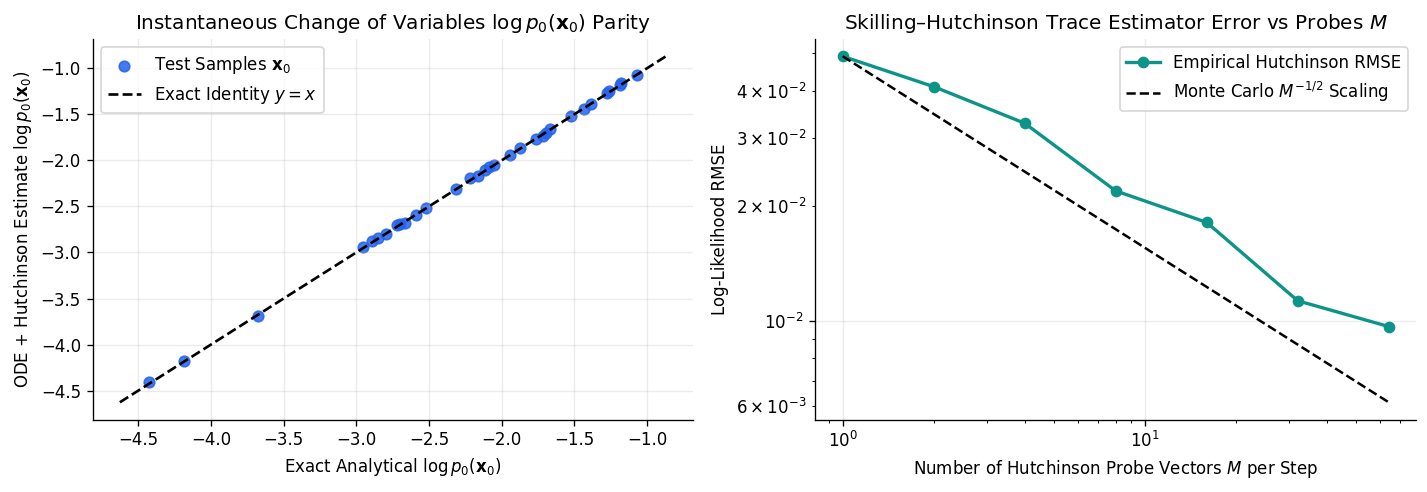

In [5]:
# Verify exact log-likelihood evaluation on a 2D linear flow v(x, t) = A x
# If dx/dt = A x on t in [0, 1] and x_1 ~ N(0, I), then x_0 = exp(-A) x_1 ~ N(0, exp(-A) exp(-A)^T).
A_flow = torch.tensor([[0.45, 0.20],
                       [-0.20, 0.35]], dtype=torch.float32)

# Generate test points x_0 in R^2
n_pts = 32
x0_pts = torch.randn(n_pts, 2) * 0.7

# 1. Ground-truth analytical log-likelihood log p_0(x_0)
# Since x_1 = exp(A) x_0 ~ N(0, I), change of variables gives:
# log p_0(x_0) = log p_N(0,I)(exp(A) x_0) + Tr(A)
exp_A = torch.matrix_exp(A_flow)
x1_true = x0_pts @ exp_A.T
log_p1_true = -0.5 * 2 * np.log(2.0 * np.pi) - 0.5 * torch.sum(x1_true ** 2, dim=-1)
log_p0_analytic = log_p1_true + torch.trace(A_flow)

# 2. Continuous ODE integration with Skilling-Hutchinson trace estimator
def hutchinson_log_likelihood(x_init, n_steps=200, n_hutch_samples=16):
    x = x_init.clone()
    dt = 1.0 / n_steps
    total_div = torch.zeros(x_init.shape[0])
    
    for _ in range(n_steps):
        x = x.detach().requires_grad_(True)
        v = x @ A_flow.T  # Velocity field v(x) = A x
        
        div_est = torch.zeros(x_init.shape[0])
        for _ in range(n_hutch_samples):
            eps = torch.randn_like(x)
            vjp = torch.autograd.grad(outputs=v, inputs=x, grad_outputs=eps, retain_graph=True)[0]
            div_est += torch.sum(vjp * eps, dim=-1) / n_hutch_samples
            
        total_div += div_est.detach() * dt
        # RK2 midpoint step for accurate trajectory integration
        with torch.no_grad():
            x_mid = x + 0.5 * dt * (x @ A_flow.T)
            x = x + dt * (x_mid @ A_flow.T)
            
    log_pT = -0.5 * 2 * np.log(2.0 * np.pi) - 0.5 * torch.sum(x ** 2, dim=-1)
    return log_pT + total_div

log_p0_hutch = hutchinson_log_likelihood(x0_pts, n_steps=200, n_hutch_samples=32)
mae_ll = torch.mean(torch.abs(log_p0_hutch - log_p0_analytic)).item()
print(f"Mean Absolute Error between Hutchinson ODE Log-Likelihood and Exact Analytic Log-Likelihood: {mae_ll:.4f}")
for i in range(4):
    print(f"  Sample {i}: Hutchinson Est = {log_p0_hutch[i].item():.4f} | Exact Analytic = {log_p0_analytic[i].item():.4f}")

# Check Hutchinson estimator standard deviation vs number of probe vectors M
M_list = [1, 2, 4, 8, 16, 32, 64]
rmse_list = []
for M in M_list:
    est_M = hutchinson_log_likelihood(x0_pts[:16], n_steps=150, n_hutch_samples=M)
    rmse = torch.sqrt(torch.mean((est_M - log_p0_analytic[:16]) ** 2)).item()
    rmse_list.append(rmse)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

axes[0].scatter(log_p0_analytic.numpy(), log_p0_hutch.numpy(), color="#2563eb", alpha=0.85, s=40, label="Test Samples $\\mathbf{x}_0$")
lims = [min(log_p0_analytic.min().item(), log_p0_hutch.min().item()) - 0.2,
        max(log_p0_analytic.max().item(), log_p0_hutch.max().item()) + 0.2]
axes[0].plot(lims, lims, "k--", lw=1.6, label="Exact Identity $y = x$")
axes[0].set_title(r"Instantaneous Change of Variables $\log p_0(\mathbf{x}_0)$ Parity")
axes[0].set_xlabel(r"Exact Analytical $\log p_0(\mathbf{x}_0)$")
axes[0].set_ylabel(r"ODE + Hutchinson Estimate $\log p_0(\mathbf{x}_0)$")
axes[0].legend(loc="upper left")

axes[1].loglog(M_list, rmse_list, "o-", color="#0d9488", lw=2.0, label="Empirical Hutchinson RMSE")
axes[1].loglog(M_list, rmse_list[0] / np.sqrt(np.array(M_list)), "k--", lw=1.5, label=r"Monte Carlo $M^{-1/2}$ Scaling")
axes[1].set_title(r"Skilling–Hutchinson Trace Estimator Error vs Probes $M$")
axes[1].set_xlabel(r"Number of Hutchinson Probe Vectors $M$ per Step")
axes[1].set_ylabel(r"Log-Likelihood RMSE")
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()